# Avaliação no fluxo do app: filtro por NER + classificador

No `05b`, o sentimento foi medido só nos comentários que os rotuladores marcaram como sobre o produto. Isso equivale a um **filtro perfeito**, que o app não tem. O fluxo testado aqui, que era a hipótese inicial do app, é:

> comentários do vídeo → **filtro** (só os que citam um produto ou marca) → **classificador de sentimento** → resumo

Aqui avaliamos esse fluxo de ponta a ponta, para decidir **qual classificador vai para o app**. Comparamos quatro cenários:

| Cenário | O que chega ao classificador |
|---|---|
| Sem filtro | todos os comentários |
| **Filtro por NER** | os comentários em que o GLiNER2 (etapa 3) encontra uma marca, produto ou empresa. **Hipótese inicial do app** (descartada; ver a conclusão) |
| Filtro por nome | os comentários que citam o produto pesquisado (nome ou apelidos, por busca de texto). Alternativa barata ao NER |
| Filtro perfeito | os comentários rotulados como sobre o produto (o resultado do `05b`) |

Não é preciso rodar os modelos de novo: as predições de todos eles, comentário a comentário, estão em `reports/05b_predicoes_youtube_todos.csv`. Só o NER roda aqui (CPU, alguns minutos).

**Gabarito:** os comentários em que os dois rotuladores concordaram, sem os 2 "mistos" (nenhum modelo tem essa classe): 86 sobre o produto (positivo, neutro ou negativo) e 88 "não é sobre o produto". Os textos não aparecem nas saídas.

In [1]:
import sys, re, time, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.metrics import f1_score, accuracy_score

RAIZ = Path("..").resolve()
sys.path.insert(0, str(RAIZ))
from src.dados import CLASSES, SEED

REPORTS = RAIZ / "reports"
pd.set_option("display.width", 200)

amostra = pd.read_csv(RAIZ / "coleta_youtube/dados/amostra_rotulagem.csv", encoding="utf-8-sig", dtype=str)
pred = pd.read_csv(REPORTS / "05b_predicoes_youtube_todos.csv", dtype=str)
C = pred[(pred["tipo"] == "comentário") & (pred["rotulo_final"] != "misto")].merge(
    amostra[["id", "produto", "texto"]], on="id")
C["sobre_produto"] = C["rotulo_final"] != "nao_sobre_produto"

SEMENTES = [c for c in pred if c.startswith("BERTimbau ajustado")]
MODELOS = ["TF-IDF + RL", "BiGRU + NILC GloVe (ajustado)", "XLM-R tweets (zero-shot)",
           "BERTimbau congelado + RL"] + SEMENTES
print(f"{len(C)} comentários: {C['sobre_produto'].sum()} sobre o produto, {(~C['sobre_produto']).sum()} não")
pd.crosstab(C["produto"], C["rotulo_final"], margins=True)

174 comentários: 86 sobre o produto, 88 não


rotulo_final,nao_sobre_produto,negativo,neutro,positivo,All
produto,,,,,
BYD Dolphin Mini,9,11,5,6,31
Havaianas,20,3,3,6,32
O Boticário (perfumes),4,8,5,13,30
PlayStation 5,9,4,8,1,22
iFood,28,2,0,0,30
iPhone 17,18,4,2,5,29
All,88,32,23,31,174


## 1. Os filtros

### 1.1 Filtro por NER
O mesmo GLiNER2 PT-BR da etapa 3. Um comentário passa se o modelo encontra **qualquer** entidade das categorias `marca`, `produto` ou `empresa` (não só o produto pesquisado), porque comparações ("melhor que o Galaxy") também são opinião sobre o produto. `empresa` entra porque marcas como iFood e BYD também são empresas, e a etapa 3 mostrou que o modelo confunde as duas.

O limiar principal é o padrão (0,5), o mesmo da etapa 3. Também mostramos outros limiares, só para ver a troca entre deixar passar ruído e perder comentários relevantes. Só a decisão (passa ou não) é guardada; os trechos encontrados não são impressos.

In [2]:
from gliner2 import AutoExtractor
extractor = AutoExtractor.from_pretrained("ottema/gliner2-ptbr")
CATEGORIAS = ["marca", "produto", "empresa"]
LIMIARES = [0.3, 0.5, 0.7, 0.9]

t0 = time.perf_counter()
confianca_max = []                               # maior confiança entre as entidades achadas no comentário
for texto in C["texto"]:
    ents = extractor.extract_entities(texto, CATEGORIAS, threshold=min(LIMIARES),
                                      include_confidence=True)["entities"]
    confs = [e["confidence"] for lista in ents.values() for e in lista]
    confianca_max.append(max(confs, default=0.0))
C["ner_conf"] = confianca_max
tempo_ner = time.perf_counter() - t0
print(f"NER em {len(C)} comentários: {tempo_ner:.1f} s ({tempo_ner / len(C) * 1000:.0f} ms por comentário, CPU)")
for t in LIMIARES:
    C[f"ner_{t}"] = C["ner_conf"] >= t

[transformers] You are using a model of type `extractor` to instantiate a model of type ``. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


NER em 174 comentários: 15.6 s (90 ms por comentário, CPU)


### 1.2 Filtro por nome
Busca, sem acento e sem diferenciar maiúsculas, o nome do produto pesquisado ou apelidos comuns. A lista foi escrita à mão, como uma empresa faria ao cadastrar o produto no app.

In [3]:
APELIDOS = {
    "Havaianas": ["havaianas", "havaiana"],
    "iPhone 17": ["iphone", "apple", "ip17", "ios"],
    "O Boticário (perfumes)": ["boticario", "boti", "malbec", "egeo", "lily", "floratta", "quasar", "zaad", "arbo"],
    "PlayStation 5": ["playstation", "ps5", "ps 5", "play 5", "sony", "dualsense"],
    "BYD Dolphin Mini": ["byd", "dolphin"],
    "iFood": ["ifood", "i food"],
}

def sem_acento(s):
    return "".join(ch for ch in unicodedata.normalize("NFD", s.lower()) if unicodedata.category(ch) != "Mn")

def cita_produto(texto, produto):
    t = sem_acento(texto)
    return any(re.search(rf"\b{re.escape(a)}\b", t) for a in APELIDOS[produto])

C["nome"] = [cita_produto(t, p) for t, p in zip(C["texto"], C["produto"])]

### 1.3 Qualidade dos filtros
- **Revocação:** dos comentários sobre o produto, quantos o filtro deixa passar.
- **Precisão:** dos comentários que passam, quantos são de fato sobre o produto (o resto é ruído que chega ao resumo).

In [4]:
FILTROS = {"Sem filtro": np.ones(len(C), bool)}
FILTROS.update({f"NER (limiar {t})": C[f"ner_{t}"].values for t in LIMIARES})
FILTROS["Nome do produto"] = C["nome"].values
FILTROS["Perfeito (rótulos)"] = C["sobre_produto"].values

def qualidade(mask):
    sobre = C["sobre_produto"].values
    passa = mask.sum()
    return {"passam": int(passa), "ruído que passa": int((mask & ~sobre).sum()),
            "precisão": (mask & sobre).sum() / passa if passa else np.nan,
            "revocação": (mask & sobre).sum() / sobre.sum()}

qual = pd.DataFrame({n: qualidade(m) for n, m in FILTROS.items()}).T
qual.round(3)

,passam,ruído que passa,precisão,revocação
Sem filtro,174.0,88.0,0.494,1.000
NER (limiar 0.3),148.0,73.0,0.507,0.872
NER (limiar 0.5),147.0,73.0,0.503,0.860
NER (limiar 0.7),143.0,71.0,0.503,0.837
NER (limiar 0.9),138.0,67.0,0.514,0.826
Nome do produto,34.0,3.0,0.912,0.360
Perfeito (rótulos),86.0,0.0,1.000,1.000


## 2. Sentimento de ponta a ponta

Para cada cenário, só os comentários que passam no filtro são avaliados, e os de ruído que passam **contam como erro** (o modelo deu um sentimento a algo que não é opinião sobre o produto). Medimos:
- **F1 macro de ponta a ponta** nas três classes;
- **Erro no resumo:** o app mostra a proporção de positivos, neutros e negativos. Comparamos a proporção prevista (nos comentários que passam) com a proporção real (nos comentários sobre o produto) e reportamos a maior diferença, em pontos percentuais. É o número que a empresa veria errado.

Para o BERTimbau ajustado, média das 3 sementes.

In [5]:
real = C.loc[C["sobre_produto"], "rotulo_final"].value_counts(normalize=True).reindex(CLASSES).fillna(0)

def avaliar(mask, modelo):
    sub = C[mask]
    y, p = sub["rotulo_final"], sub[modelo]
    prop = p.value_counts(normalize=True).reindex(CLASSES).fillna(0)
    return {"f1_macro": f1_score(y, p, labels=CLASSES, average="macro", zero_division=0),
            "acuracia": accuracy_score(y, p),
            "erro_resumo_pp": 100 * (prop - real).abs().max()}

linhas = []
for nf, mask in FILTROS.items():
    for m in MODELOS:
        linhas.append({"filtro": nf, "modelo": m.replace(m[m.find(" (semente"):], "") if "semente" in m else m,
                       **avaliar(mask, m)})
res = pd.DataFrame(linhas).groupby(["filtro", "modelo"], sort=False).mean().reset_index()
res.to_csv(REPORTS / "05c_resultados_fluxo_app.csv", index=False)
print("Proporção real nos comentários sobre o produto:", (100 * real).round(1).to_dict())
res.pivot(index="modelo", columns="filtro", values="f1_macro").loc[:, list(FILTROS)].round(3)

Proporção real nos comentários sobre o produto: {'positivo': 36.0, 'neutro': 26.7, 'negativo': 37.2}


filtro,Sem filtro,NER (limiar 0.3),NER (limiar 0.5),NER (limiar 0.7),NER (limiar 0.9),Nome do produto,Perfeito (rótulos)
modelo,,,,,,,
BERTimbau ajustado,0.521,0.536,0.541,0.538,0.544,0.656,0.788
BERTimbau congelado + RL,0.533,0.543,0.548,0.545,0.553,0.706,0.807
BiGRU + NILC GloVe (ajustado),0.488,0.485,0.490,0.486,0.499,0.671,0.739
TF-IDF + RL,0.505,0.501,0.507,0.503,0.508,0.595,0.744
XLM-R tweets (zero-shot),0.513,0.510,0.515,0.512,0.517,0.711,0.774


In [6]:
res.pivot(index="modelo", columns="filtro", values="erro_resumo_pp").loc[:, list(FILTROS)].round(1)

filtro,Sem filtro,NER (limiar 0.3),NER (limiar 0.5),NER (limiar 0.7),NER (limiar 0.9),Nome do produto,Perfeito (rótulos)
modelo,,,,,,,
BERTimbau ajustado,5.5,5.4,5.2,5.8,5.6,19.4,10.5
BERTimbau congelado + RL,6.2,7.0,6.8,7.4,7.8,18.7,8.1
BiGRU + NILC GloVe (ajustado),7.0,6.7,7.0,8.2,8.4,15.7,10.5
TF-IDF + RL,19.1,20.2,20.6,22.2,21.5,30.4,16.3
XLM-R tweets (zero-shot),7.9,8.2,8.6,8.9,8.0,3.2,5.8


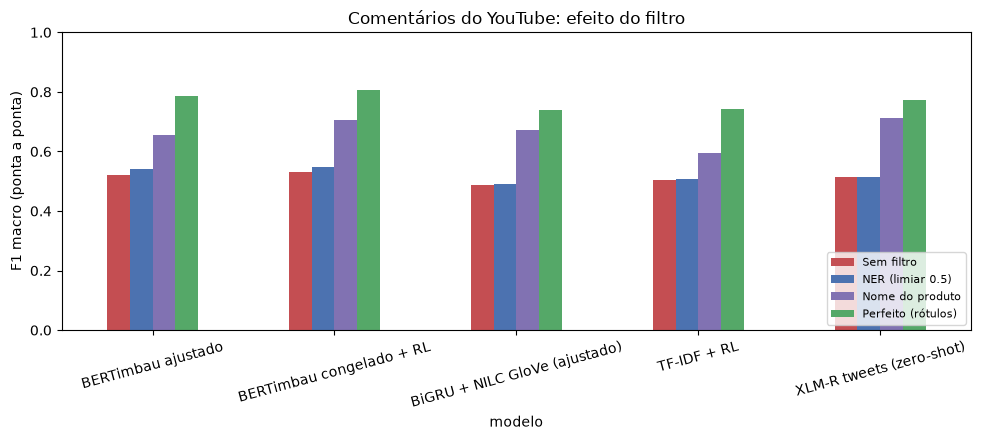

In [7]:
principais = ["Sem filtro", "NER (limiar 0.5)", "Nome do produto", "Perfeito (rótulos)"]
tab = res[res["filtro"].isin(principais)].pivot(index="modelo", columns="filtro", values="f1_macro")[principais]
tab.plot.bar(figsize=(10, 4.5), rot=15, color=["#C44E52", "#4C72B0", "#8172B2", "#55A868"])
plt.ylabel("F1 macro (ponta a ponta)"); plt.ylim(0, 1); plt.title("Comentários do YouTube: efeito do filtro")
plt.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

## 3. A diferença entre os modelos é significativa?

Com poucos comentários, poucos acertos a mais mudam bastante o F1. Dois testes, cada modelo contra o TF-IDF, no fluxo do app (filtro por NER, limiar 0,5) e no filtro perfeito:
- **Bootstrap pareado** (5.000 reamostragens dos comentários): intervalo de 95% para a diferença de F1 macro. Se o intervalo inclui o zero, a diferença não é significativa.
- **Teste de McNemar** (exato): olha só os comentários em que um modelo acerta e o outro erra.

Para o BERTimbau ajustado, usamos a semente 42.

In [8]:
rng = np.random.default_rng(SEED)

def comparar(mask, a, b, n_boot=5000):
    sub = C[mask]
    y, pa, pb = sub["rotulo_final"].values, sub[a].values, sub[b].values
    f1 = lambda yy, pp: f1_score(yy, pp, labels=CLASSES, average="macro", zero_division=0)
    difs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        difs.append(f1(y[i], pb[i]) - f1(y[i], pa[i]))
    so_b, so_a = int(((pb == y) & (pa != y)).sum()), int(((pa == y) & (pb != y)).sum())
    p = binomtest(so_b, so_b + so_a).pvalue if so_a + so_b else 1.0
    lo, hi = np.percentile(difs, [2.5, 97.5])
    return {"n": len(y), "dif_f1": f1(y, pb) - f1(y, pa), "IC95_inf": lo, "IC95_sup": hi,
            f"só {b.split(' ')[0]} acerta": so_b, "só TF-IDF acerta": so_a, "p_mcnemar": p}

linhas = []
for nf in ["NER (limiar 0.5)", "Perfeito (rótulos)"]:
    for m in ["BiGRU + NILC GloVe (ajustado)", "XLM-R tweets (zero-shot)", "BERTimbau congelado + RL",
              "BERTimbau ajustado (semente 42)"]:
        r = comparar(FILTROS[nf], "TF-IDF + RL", m)
        linhas.append({"filtro": nf, "modelo vs TF-IDF": m, "n": r["n"], "dif_f1": r["dif_f1"],
                       "IC95_inf": r["IC95_inf"], "IC95_sup": r["IC95_sup"],
                       "só o modelo acerta": list(r.values())[4], "só o TF-IDF acerta": r["só TF-IDF acerta"],
                       "p_mcnemar": r["p_mcnemar"]})
sig = pd.DataFrame(linhas)
sig["significativo (5%)"] = (sig["IC95_inf"] > 0) | (sig["IC95_sup"] < 0)
sig.to_csv(REPORTS / "05c_significancia.csv", index=False)
sig.round(3)

,filtro,modelo vs TF-IDF,n,dif_f1,IC95_inf,IC95_sup,só o modelo acerta,só o TF-IDF acerta,p_mcnemar,significativo (5%)
0,NER (limiar 0.5),BiGRU + NILC GloVe (ajustado),147,-0.017,-0.103,0.072,9,8,1.000,False
1,NER (limiar 0.5),XLM-R tweets (zero-shot),147,0.009,-0.073,0.095,11,9,0.824,False
2,NER (limiar 0.5),BERTimbau congelado + RL,147,0.041,-0.037,0.121,11,5,0.210,False
3,NER (limiar 0.5),BERTimbau ajustado (semente 42),147,0.014,-0.067,0.098,10,6,0.454,False
4,Perfeito (rótulos),BiGRU + NILC GloVe (ajustado),86,-0.004,-0.124,0.117,10,9,1.000,False
5,Perfeito (rótulos),XLM-R tweets (zero-shot),86,0.030,-0.074,0.137,12,10,0.832,False
6,Perfeito (rótulos),BERTimbau congelado + RL,86,0.064,-0.041,0.170,12,7,0.359,False
7,Perfeito (rótulos),BERTimbau ajustado (semente 42),86,0.018,-0.100,0.137,11,8,0.648,False


## 4. Custo de cada peça no app

Tempo por comentário na CPU (onde o app roda), das etapas 4 e 5, mais o NER medido acima. Para um vídeo com algumas centenas de comentários, multiplique por ~300.

In [9]:
custo = pd.concat([pd.read_csv(REPORTS / "04_resultados_rede_neural.csv"),
                   pd.read_csv(REPORTS / "05_resultados_transformers.csv")]).set_index("configuração")
ms = custo["inferencia_cpu_ms"].fillna(custo["inferencia_ms"]) if "inferencia_cpu_ms" in custo else custo["inferencia_ms"]
custo_tab = pd.DataFrame({"ms por comentário (CPU)": ms,
                          "parâmetros": custo["param_total"]}).loc[
    ["TF-IDF + RL (etapa 2)", "BiGRU + NILC GloVe (ajustado)", "XLM-R tweets (zero-shot)",
     "BERTimbau congelado + RL", "BERTimbau ajustado"]]
custo_tab.loc["NER (GLiNER2), filtro"] = [tempo_ner / len(C) * 1000, np.nan]
custo_tab["300 comentários (s)"] = custo_tab["ms por comentário (CPU)"] * 300 / 1000
custo_tab.round(1)

,ms por comentário (CPU),parâmetros,300 comentários (s)
configuração,,,
TF-IDF + RL (etapa 2),0.4,53310.0,0.1
BiGRU + NILC GloVe (ajustado),8.9,15523311.0,2.7
XLM-R tweets (zero-shot),205.0,278045955.0,61.5
BERTimbau congelado + RL,168.2,108925443.0,50.5
BERTimbau ajustado,174.1,108925443.0,52.2
"NER (GLiNER2), filtro",89.6,NaN,26.9


## 5. Conclusão

**1. O NER não serve como filtro de relevância.** O GLiNER2 encontra alguma marca, produto ou empresa em ~85% dos comentários, e metade do que passa é ruído: a precisão (~0,50) é a mesma de não filtrar, em qualquer limiar. Testamos também cada categoria isolada (`marca`, `produto`, `empresa`) e as categorias específicas da etapa 3: a precisão ficou entre 0,50 e 0,53 em todas. Comentários do YouTube citam outras marcas, o youtuber e objetos comuns o tempo todo; citar uma entidade não indica que o comentário é opinião sobre o produto.

**2. O filtro por nome é preciso, mas perde a maioria.** Dos comentários que citam o produto pesquisado, 91% são de fato sobre ele. Mas só 36% dos comentários sobre o produto citam o nome: os outros 64% falam do produto sem nomeá-lo ("a bateria dura quanto?"). Isso confirma, com números, a limitação 4 da nota.

**3. Nenhum modelo é significativamente melhor que o TF-IDF**, nem no fluxo com o filtro por NER nem com o filtro perfeito. Todos os intervalos de 95% incluem o zero e todos os p de McNemar ficam acima de 0,2. A maior diferença (BERTimbau congelado, +0,04 a +0,06 de F1) corresponde a 5 ou 6 comentários a mais acertados.

**4. Mas o TF-IDF distorce o resumo.** Sem filtro, com o filtro por NER e com o filtro perfeito, a proporção de positivos, neutros e negativos que ele mostra se afasta 16 a 22 pontos percentuais da real, contra 5 a 11 dos outros modelos. Com o filtro por nome (34 comentários), todos erram mais: 30 pp o TF-IDF, 16 a 19 pp a BiGRU e os BERTimbau, e 3 pp o XLM-R. Em parte, é por mandar o ruído para "negativo" (59% dos comentários fora do produto). Essa métrica também é ruidosa com esta amostra, mas a diferença é grande e consistente em todos os cenários.

**5. Custo:** para 300 comentários na CPU, o TF-IDF leva 0,1 s, a BiGRU ~3 s e os Transformers ~50 a 60 s, mais ~27 s do NER.

A escolha do modelo e da separação dos comentários no app está em `docs/notas/decisoes_de_escopo.md`: BERTimbau congelado + RL, separação pela busca do nome e NER só para listar as marcas citadas.
